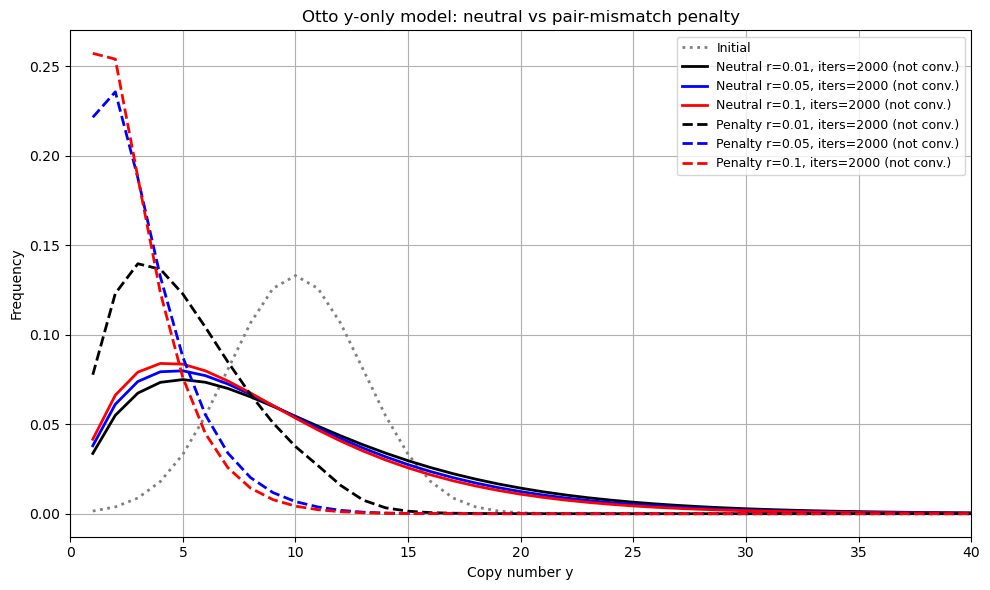

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------------
# Parameters
# -------------------------
recomb_rates = [0.01, 0.05, 0.1]
colors = ['black', 'blue', 'red']
k_vals = np.arange(1, 51)

# -------------------------
# Pair-mismatch penalty
# -------------------------
def approx_sel_penalty_pair(y1, y2, threshold=10, penalty_strength=0.01):
    """
    Pair-specific penalty depending only on parental copy-number mismatch.

    Biological interpretation:
    parental copy-number mismatch reduces the effective long-term
    contribution of that parental pair.
    """
    diff = abs(y1 - y2)
    if diff > threshold:
        penalty = 1.0 - penalty_strength * (diff - threshold)
    else:
        penalty = 1.0
    return np.clip(penalty, 0.0, 1.0)

# -------------------------
# Trapezoid Probability
# -------------------------
def trapez(k, y1, y2):
    """
    Otto-style trapezoid recombination kernel for given parental copy numbers y1, y2.
    Returns P(k | recombinant outcome from y1, y2).
    """
    result = np.zeros_like(k, dtype=float)

    result[(k <= y1) & (k <= y2)] = k[(k <= y1) & (k <= y2)]
    result[(k <= y1) & (k > y2)] = y2
    result[(k > y1) & (k <= y2)] = y1
    result[(k > y1) & (k > y2)] = y1 + y2 - k[(k > y1) & (k > y2)]

    result[(k < 1) | (k > (y1 + y2 - 1))] = 0.0
    return result / (y1 * y2)

# -------------------------
# Conditional Probabilities
# -------------------------
def conditional_prob(k, r, y1, y2):
    """
    Full one-generation offspring distribution from parental pair (y1, y2):
      - with probability (1-r): non-recombinant inheritance
      - with probability r: recombinant outcome from trapezoid kernel
    """
    prob = np.zeros_like(k, dtype=float)

    # no recombination contribution
    if y1 == y2:
        prob[k == y1] = 1.0 - r
    else:
        prob[k == y1] += 0.5 * (1.0 - r)
        prob[k == y2] += 0.5 * (1.0 - r)

    # recombination contribution
    prob += r * trapez(k, y1, y2)
    return prob

# -------------------------
# Neutral Otto update
# -------------------------
def f_post_neutral(k_vals, r, f_prior):
    """
    One-generation update under the neutral Otto y-only model.
    """
    n = len(k_vals)
    f_new = np.zeros(n)

    for i, y1 in enumerate(k_vals):
        for j, y2 in enumerate(k_vals):
            weight = f_prior[i] * f_prior[j]
            f_new += weight * conditional_prob(k_vals, r, y1, y2)

    total = np.sum(f_new)
    if total <= 0:
        raise ValueError("Total frequency became zero in neutral update.")
    return f_new / total

# -------------------------
# Pair-mismatch penalty update
# -------------------------
def f_post_penalty(k_vals, r, f_prior, threshold=10, penalty_strength=0.01):
    """
    One-generation update with pair-specific parental mismatch penalty.
    """
    n = len(k_vals)
    f_new = np.zeros(n)

    for i, y1 in enumerate(k_vals):
        for j, y2 in enumerate(k_vals):
            weight = f_prior[i] * f_prior[j]

            # pair-specific parental mismatch penalty
            weight *= approx_sel_penalty_pair(
                y1, y2,
                threshold=threshold,
                penalty_strength=penalty_strength
            )

            f_new += weight * conditional_prob(k_vals, r, y1, y2)

    total = np.sum(f_new)
    if total <= 0:
        raise ValueError("Total frequency became zero in penalty update. Adjust parameters.")
    return f_new / total

# -------------------------
# Iteration
# -------------------------
def iterate_until_convergence(k_vals, r, f0, model="neutral",
                              threshold=10, penalty_strength=0.01,
                              tol=1e-8, max_iter=2000):
    """
    Iterate either neutral or penalty model until convergence.
    """
    f = f0 / f0.sum()

    for it in range(1, max_iter + 1):
        if model == "neutral":
            f_new = f_post_neutral(k_vals, r, f)
        elif model == "penalty":
            f_new = f_post_penalty(
                k_vals, r, f,
                threshold=threshold,
                penalty_strength=penalty_strength
            )
        else:
            raise ValueError("model must be 'neutral' or 'penalty'")

        diff = np.abs(f_new - f).sum()
        f = f_new

        if diff < tol:
            return f, it, True

    return f, max_iter, False

# -------------------------
# Run simulations
# -------------------------
def run_simulation(model="neutral",
                   init_mean=10, init_std=3,
                   threshold=10, penalty_strength=0.01):
    """
    Run one converged distribution for each recombination rate.
    """
    init = np.exp(-0.5 * ((k_vals - init_mean) / init_std) ** 2)
    init /= init.sum()

    results = []
    for r, color in zip(recomb_rates, colors):
        f_eq, iters, ok = iterate_until_convergence(
            k_vals, r, init,
            model=model,
            threshold=threshold,
            penalty_strength=penalty_strength
        )
        results.append((k_vals, f_eq, r, color, iters, ok))
    return init, results

# -------------------------
# Plotting
# -------------------------
def plot_results(results, label_prefix, linestyle='-'):
    for k, dist, r, color, iters, ok in results:
        status = f"{iters}" if ok else f"{iters} (not conv.)"
        plt.plot(
            k, dist,
            label=f"{label_prefix} r={r}, iters={status}",
            color=color,
            linestyle=linestyle,
            linewidth=2
        )

# -------------------------
# Execute and plot
# -------------------------
if __name__ == "__main__":
    init, neutral_results = run_simulation(
        model="neutral",
        init_mean=10,
        init_std=3
    )

    _, penalty_results = run_simulation(
        model="penalty",
        init_mean=10,
        init_std=3,
        threshold=10,
        penalty_strength=0.02
    )

    plt.figure(figsize=(10, 6))

    plt.plot(k_vals, init, color="gray", linestyle=":", linewidth=2, label="Initial")

    plot_results(neutral_results, "Neutral", linestyle='-')
    plot_results(penalty_results, "Penalty", linestyle='--')

    plt.xlabel("Copy number y")
    plt.ylabel("Frequency")
    plt.title("Otto y-only model: neutral vs pair-mismatch penalty")
    plt.legend(fontsize=9)
    plt.grid(True)
    plt.xlim(0, 40)
    plt.tight_layout()
    plt.show()
 



In [3]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------------
# Parameters
# -------------------------
sx = 0.02
sy = 0.005
eps = 0.05
recomb_rates = [0.01, 0.05, 0.1]
colors = ["black", "blue", "#CC79A7"]
k_vals = np.arange(1, 51)

# -------------------------
# Selection Functions
# -------------------------
def approx_sel_classic(y, sx=sx, sy=sy, eps=eps):
    s_tilde = eps * np.exp(-eps) * np.sqrt(sx * sy)
    y_opt = ((np.log(sx) - np.log(sy)) / (2 * eps)) + 1
    return np.maximum(0, 1 - s_tilde * (y - y_opt) ** 2)

def approx_sel_penalty(diff, threshold=15, penalty_strength=0.01):
    excess = max(0, diff - threshold)
    return max(0, 1 - penalty_strength * excess)

# -------------------------
# Trapezoid Probability
# -------------------------
def trapez(k, y1, y2):
    result = np.zeros_like(k, dtype=float)
    result[(k <= y1) & (k <= y2)] = k[(k <= y1) & (k <= y2)]
    result[(k <= y1) & (k > y2)] = y2
    result[(k > y1) & (k <= y2)] = y1
    result[(k > y1) & (k > y2)] = y1 + y2 - k[(k > y1) & (k > y2)]
    result[(k < 1) | (k > (y1 + y2 - 1))] = 0
    return result / (y1 * y2)

# -------------------------
# Conditional Probabilities
# -------------------------
def conditional_prob(k, r, y1, y2):
    prob = np.zeros_like(k, dtype=float)
    if y1 == y2:
        prob[k == y1] = 1 - r
    else:
        prob[k == y1] += 0.5 * (1 - r)
        prob[k == y2] += 0.5 * (1 - r)
    prob += r * trapez(k, y1, y2)
    return prob

# -------------------------
# f_post: Update Distribution
# -------------------------
def f_post(k_vals, r, f_prior, selection_type="classic"):
    n = len(k_vals)
    f_new = np.zeros(n)

    for i, y1 in enumerate(k_vals):
        for j, y2 in enumerate(k_vals):
            weight = f_prior[i] * f_prior[j]

            if selection_type == "classic":
                weight *= approx_sel_classic(y1) * approx_sel_classic(y2)

            elif selection_type == "penalty":
                diff = abs(y1 - y2)
                weight *= approx_sel_penalty(diff)

            f_new += weight * conditional_prob(k_vals, r, y1, y2)

    return f_new / np.sum(f_new)

# -------------------------
# Run Simulation
# -------------------------
def run_simulation(selection_type, init_mean=10, init_std=3, max_iter=2000, tol=1e-6):
    init = np.exp(-0.5 * ((k_vals - init_mean) / init_std) ** 2)
    init /= init.sum()
    results = []

    for r, color in zip(recomb_rates, colors):
        prev = init.copy()
        for step in range(max_iter):
            updated = f_post(k_vals, r, prev, selection_type=selection_type)
            if np.max(np.abs(updated - prev)) < tol:
                break
            prev = updated

        mean = np.sum(k_vals * updated)
        results.append((k_vals, init, updated, r, color, mean, step + 1))

    return results



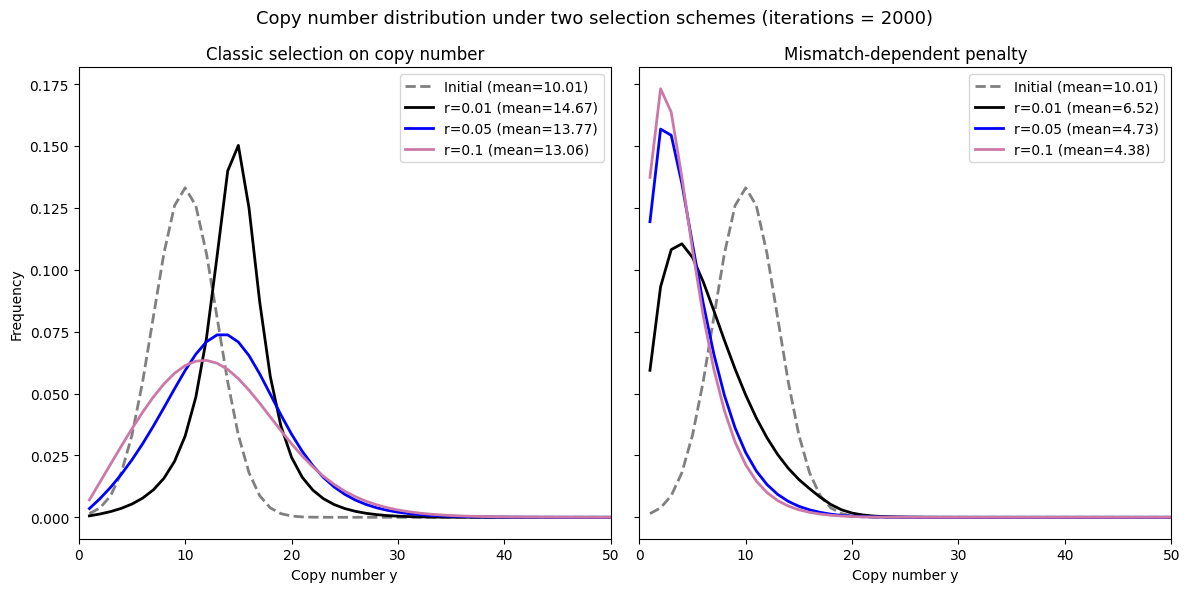

In [4]:
# -------------------------
# Plotting
# -------------------------
def plot_results(ax, results, panel_title, linestyle="-"):
    init = results[0][1]
    mean0 = np.sum(k_vals * init)

    ax.plot(
        k_vals, init,
        color="gray", linestyle="--", lw=2,
        label=f"Initial (mean={mean0:.2f})"
    )

    for k, init, dist, r, color, mean, steps in results:
        ax.plot(
            k, dist,
            color=color, linestyle=linestyle, lw=2,
            label=f"r={r} (mean={mean:.2f})"
        )

    ax.set_title(panel_title)
    ax.set_xlabel("Copy number y")
    ax.set_xlim(0, 50)
    ax.legend()

# -------------------------
# Execute
# -------------------------
classic_results = run_simulation("classic", init_mean=10, init_std=3)
penalty_results = run_simulation("penalty", init_mean=10, init_std=3)

fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

plot_results(axes[0], classic_results, "Classic selection on copy number", linestyle="-")
plot_results(axes[1], penalty_results, "Mismatch-dependent penalty", linestyle="-")

axes[0].set_ylabel("Frequency")
fig.suptitle("Copy number distribution under two selection schemes (iterations = 2000)", fontsize=13)
plt.savefig("y_only_stractural_selection.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()